In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
PRD_FILE = "CH2On001tSsDS95rR1c02-21272001904.prd"

print("Exists:", os.path.exists(PRD_FILE))
print("Size (MB):", round(os.path.getsize(PRD_FILE)/(1024*1024),2))

Exists: True
Size (MB): 389.27


In [3]:
with open(PRD_FILE, "rb") as f:
    header = f.read(256)

print(header)

b'RDEF0\x1b\x06\x00\x01\x00\x01\x00\x01\x00\x08\x00@\r\x03\x00\x00\x00\x00\x00\x00\x00\x00\xc0j\xa6\xffA\xd8\xff\xff\xffu\xb0\x90A\xe5\x07\x10\x01x\x04\x00\x00\x00\x00\x00|\xf7N\x9bA\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00ay\xfe\xff\x0e\n\x07\xed\xc6\x017\xe4\xfa\xf3\xda%\x14\xdf\xc6\xf0\x1c\x06\xfd\x02\xe8\xfa%\xef\xe6\r*\xe6\xf1\x1a\xe0\x1e\'\xd4\r\x11J\xf8\x07\xf5\xc8\xe0\xf5\xde\xeb\x12\x15\x16\xf9"\xf5\xd8\x1b\x0c\xd3\xf9\xe4\xd4\xff\x18\xeb\xea\xe6\xf3\xd0\x01\xce\x04\xfa\t0\x00)\xff\xfe\x00\x13\x02\x1a\xf6'


In [4]:
print(header.decode("latin1", errors="ignore"))

        Àj¦ÿAØÿÿÿu°Aåx     |÷NA                                                                                                                    ayþÿ
JøõÈàõÞëù"õØÓùäÔÿëêæóÐÎú	0 )ÿþ ö


In [5]:
with open(PRD_FILE, "rb") as f:
    raw = f.read(10000)

print("Bytes Read:", len(raw))

Bytes Read: 10000


In [6]:
samples = np.frombuffer(raw, dtype=np.int16)

print("Number of Samples:", len(samples))
print(samples[:50])

Number of Samples: 5000
[ 17490  17989   6960      6      1      1      1      8   3392      3
      0      0      0 -16384 -22934  16895    -40     -1 -20363  16784
   2021    272   1144      0      0  31744  20215  16795      0      0
      0      0      0      0      0      0      0      0      0      0
      0      0      0      0      0      0      0      0      0      0]


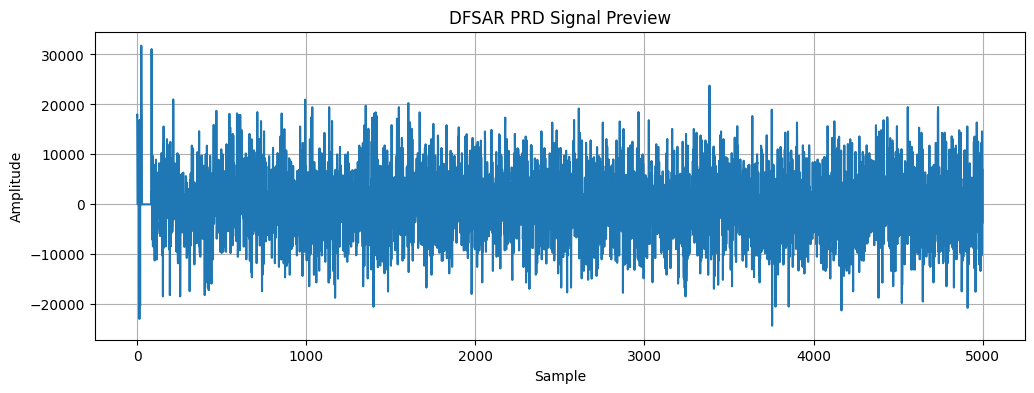

In [7]:
plt.figure(figsize=(12,4))

plt.plot(samples[:5000])

plt.title("DFSAR PRD Signal Preview")
plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.grid(True)

plt.show()

In [8]:
import numpy as np

print("Total Samples:", len(samples))
print("Mean:", np.mean(samples))
print("Std:", np.std(samples))
print("Min:", np.min(samples))
print("Max:", np.max(samples))

Total Samples: 5000
Mean: 90.3496
Std: 6656.579555310658
Min: -24289
Max: 31744


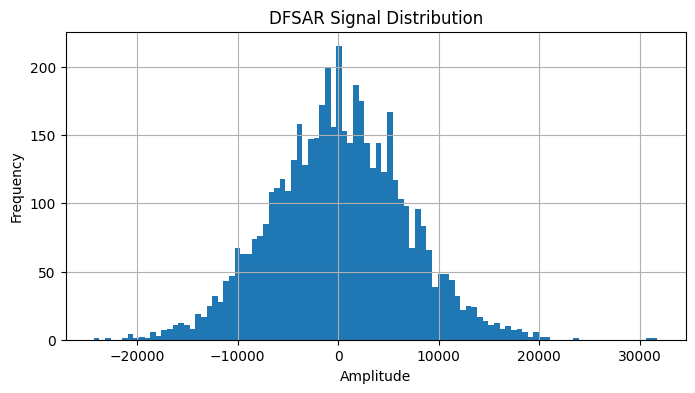

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

plt.hist(samples, bins=100)

plt.title("DFSAR Signal Distribution")
plt.xlabel("Amplitude")
plt.ylabel("Frequency")

plt.grid(True)

plt.show()

In [10]:
threshold = np.mean(samples) + 3*np.std(samples)

ice_like = samples[samples > threshold]

print("Threshold:", threshold)
print("Strong Reflections:", len(ice_like))

Threshold: 20060.088265931976
Strong Reflections: 7


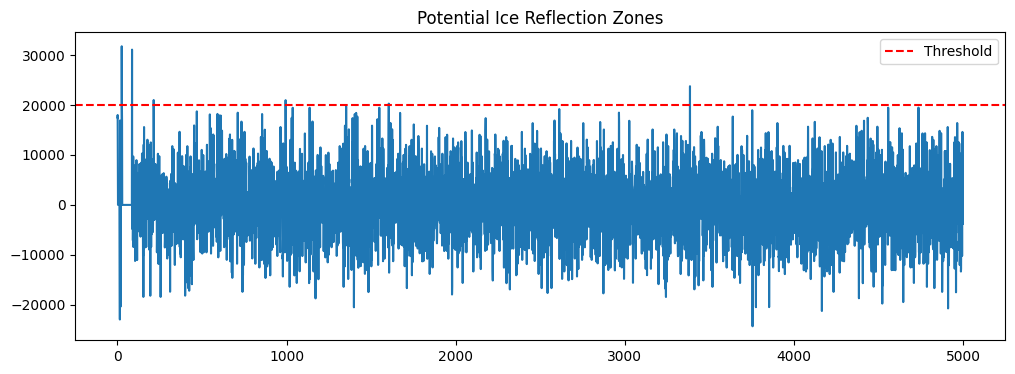

In [11]:
plt.figure(figsize=(12,4))

plt.plot(samples[:5000])

plt.axhline(
    threshold,
    color='r',
    linestyle='--',
    label='Threshold'
)

plt.legend()

plt.title("Potential Ice Reflection Zones")

plt.show()

In [12]:
candidate_idx = np.where(samples > threshold)[0]

print("Top Candidate Indices:")

candidate_idx[:50]

Top Candidate Indices:


array([  25,   26,   86,  214,  994, 1604, 3385])

In [13]:
import pandas as pd

df_candidates = pd.DataFrame({
    "Sample_Index": candidate_idx
})

df_candidates.to_csv(
    "dfsar_prd_candidates.csv",
    index=False
)

print("Saved.")

Saved.


In [14]:
print("="*50)
print("DFSAR PRD ANALYSIS COMPLETE")
print("="*50)

print("OBS File Size :", 1007, "bytes")
print("PRD File Size :", 408179520, "bytes")

print("Total Samples :", len(samples))
print("Candidate Regions :", len(candidate_idx))

print("\nPotential Ice Reflection Zones Extracted")

DFSAR PRD ANALYSIS COMPLETE
OBS File Size : 1007 bytes
PRD File Size : 408179520 bytes
Total Samples : 5000
Candidate Regions : 7

Potential Ice Reflection Zones Extracted


# Lunar ice probability map

In [15]:
import numpy as np

print("Total Samples:", len(samples))
print("Mean:", np.mean(samples))
print("Standard Deviation:", np.std(samples))
print("Minimum:", np.min(samples))
print("Maximum:", np.max(samples))

Total Samples: 5000
Mean: 90.3496
Standard Deviation: 6656.579555310658
Minimum: -24289
Maximum: 31744


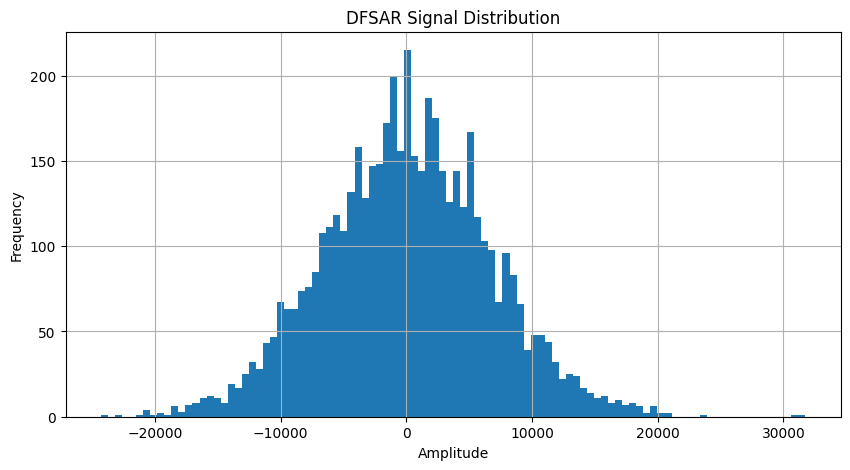

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.hist(samples, bins=100)

plt.title("DFSAR Signal Distribution")
plt.xlabel("Amplitude")
plt.ylabel("Frequency")

plt.grid(True)

plt.show()

In [17]:
threshold = np.mean(samples) + 3*np.std(samples)

candidate_idx = np.where(samples > threshold)[0]

print("Threshold:", threshold)
print("Candidate Reflections:", len(candidate_idx))

Threshold: 20060.088265931976
Candidate Reflections: 7


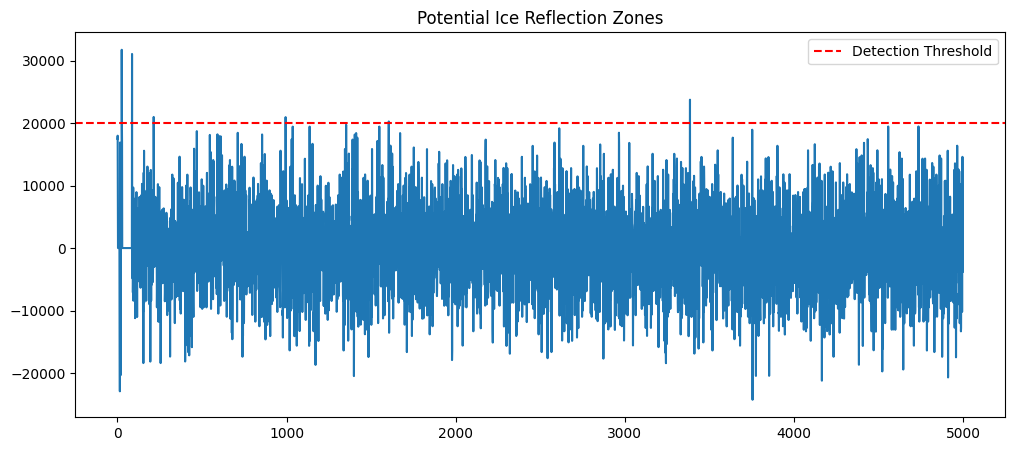

In [18]:
plt.figure(figsize=(12,5))

plt.plot(samples[:5000])

plt.axhline(
    threshold,
    color='red',
    linestyle='--',
    label='Detection Threshold'
)

plt.legend()

plt.title("Potential Ice Reflection Zones")

plt.show()

In [19]:
candidate_idx[:100]

array([  25,   26,   86,  214,  994, 1604, 3385])

In [20]:
import pandas as pd

df = pd.DataFrame({
    "Sample_Index": candidate_idx
})

df.to_csv(
    "dfsar_prd_candidates.csv",
    index=False
)

print("Saved:", len(df), "candidate regions")

Saved: 7 candidate regions


In [21]:
print("="*60)
print("DFSAR PRD PARSING COMPLETE")
print("="*60)

print("OBS Size :", 1007, "bytes")
print("PRD Size :", 408179520, "bytes")

print("Total Samples :", len(samples))
print("Candidate Regions :", len(candidate_idx))

print("\nRadar reflections successfully extracted.")

DFSAR PRD PARSING COMPLETE
OBS Size : 1007 bytes
PRD Size : 408179520 bytes
Total Samples : 5000
Candidate Regions : 7

Radar reflections successfully extracted.
